Libraries imported successfully!

Dataset loaded successfully!
Dataset Shape: (2144, 11)


,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals
0,AFG,Afghanistan,1964,8,8,22.0,161.0,64.2,0,0.0,0.0
1,AFG,Afghanistan,1968,5,5,23.2,170.2,70.0,0,0.0,0.0
2,AFG,Afghanistan,1972,8,8,29.0,168.3,63.8,0,0.0,0.0
3,AFG,Afghanistan,1980,11,11,23.6,168.4,63.2,0,0.0,0.0
4,AFG,Afghanistan,2004,5,5,18.6,170.8,64.8,0,0.0,0.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2144 entries, 0 to 2143
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           2144 non-null   object 
 1   country        2144 non-null   object 
 2   year           2144 non-null   int64  
 3   events         2144 non-null   int64  
 4   athletes       2144 non-null   int64  
 5   age            2144 non-null   float64
 6   height         2144 non-null   float64
 7   weight         2144 non-null   float64
 8   medals         2144 non-null   int64  
 9   prev_medals    2014 non-null   float64
 10  prev_3_medals  2014 non-null   float64
dtypes: float64(5), int64(4), object(2)
memory usage: 184.4+ KB

Missing Values:
team               0
country            0
year               0
events             0
athletes           0
age                0
height             0
weight             0
medals             0
prev_medals      130
prev_3_m

,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals
count,2144.000000,2144.000000,2144.000000,2144.000000,2144.000000,2144.000000,2144.000000,2014.000000,2014.000000
mean,1994.507463,35.724813,73.693097,24.778591,173.900233,69.271595,10.556437,10.248759,9.449901
std,15.384205,49.490270,127.907577,2.808559,5.357367,7.606507,33.028143,31.951920,28.232227
min,1964.000000,1.000000,1.000000,17.000000,151.000000,43.000000,0.000000,0.000000,0.000000
25%,1984.000000,6.000000,7.000000,23.275000,170.500000,64.500000,0.000000,0.000000,0.000000
50%,1996.000000,13.000000,19.000000,24.700000,174.400000,69.400000,0.000000,0.000000,0.300000
75%,2008.000000,44.000000,70.250000,26.100000,177.300000,73.400000,4.000000,4.000000,4.650000
max,2016.000000,270.000000,839.000000,66.000000,193.000000,148.000000,442.000000,442.000000,314.000000



Missing values handled!
team               0
country            0
year               0
events             0
athletes           0
age                0
height             0
weight             0
medals             0
prev_medals        0
prev_3_medals    130
dtype: int64


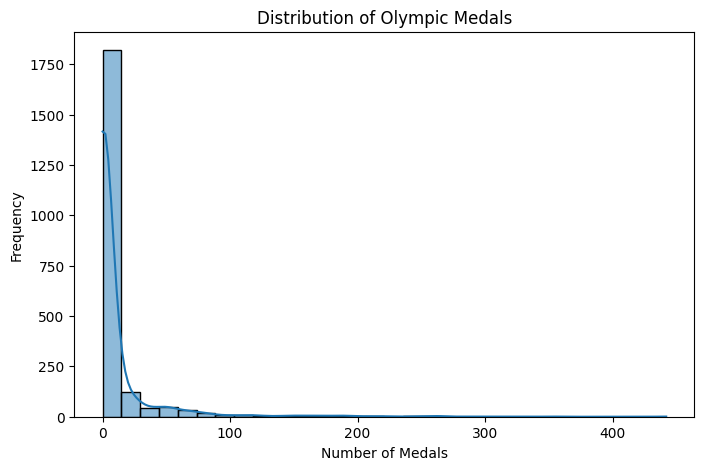

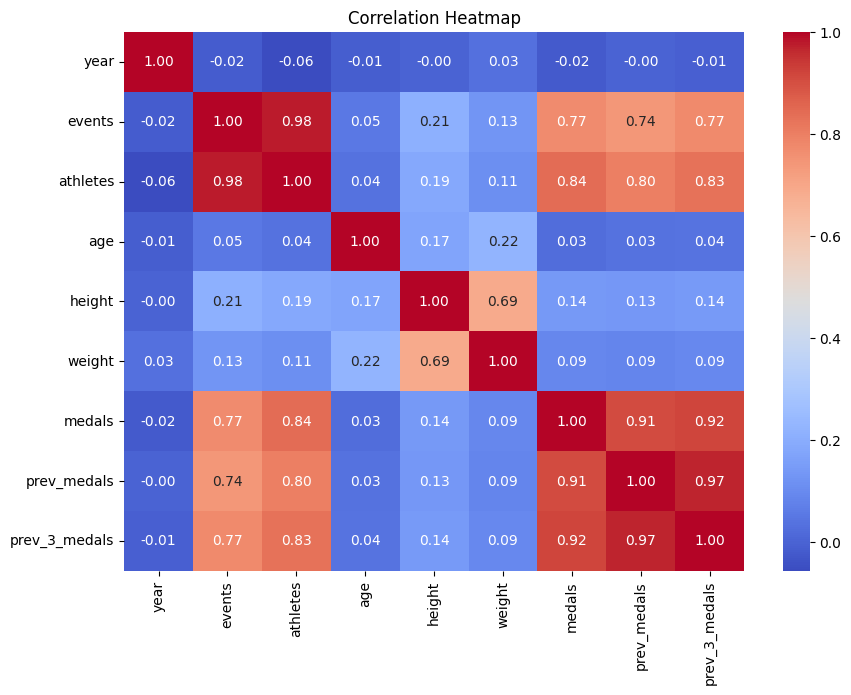

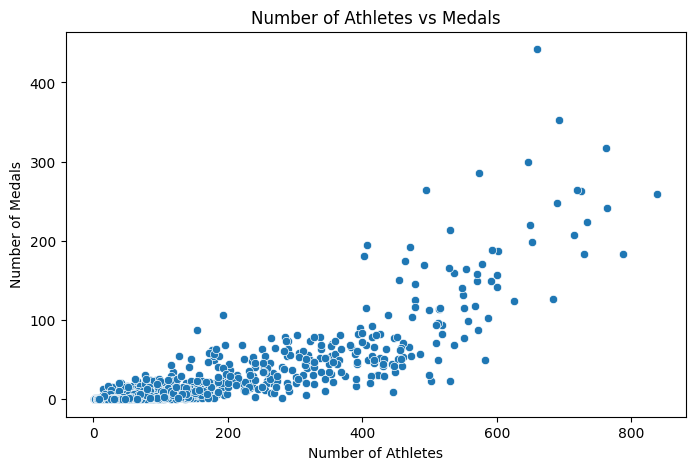


Selected Features:
['athletes', 'prev_medals']

Target Variable: medals

Training Data Shape: (1736, 2)
Testing Data Shape: (408, 2)

Linear Regression Model Trained Successfully!
Model Coefficients: [0.08285943 0.7115457 ]
Model Intercept: -2.3434230526514863

Actual vs Predicted Medals:


,Actual Medals,Predicted Medals
0,1,-1.134721
1,0,-1.383299
2,0,-1.514829
3,0,-1.846266
4,1,2.311186
5,2,4.499720
6,0,-1.846266
7,0,-2.011985
8,0,0.556657
9,0,-0.189078



MODEL PERFORMANCE
-------------------------
MAE: 4.322088753481257
MSE: 67.0088162083483
RMSE: 8.185891289795407
R2 Score: 0.9185916946316627


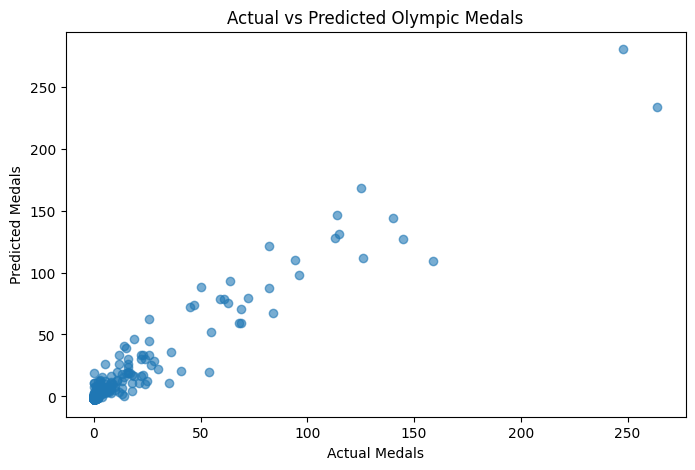

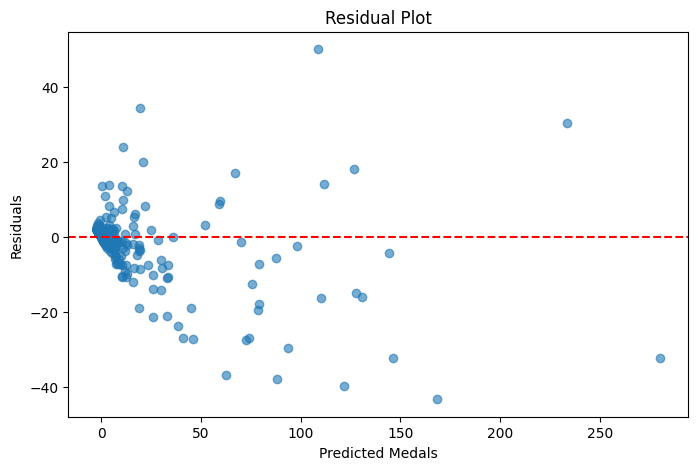

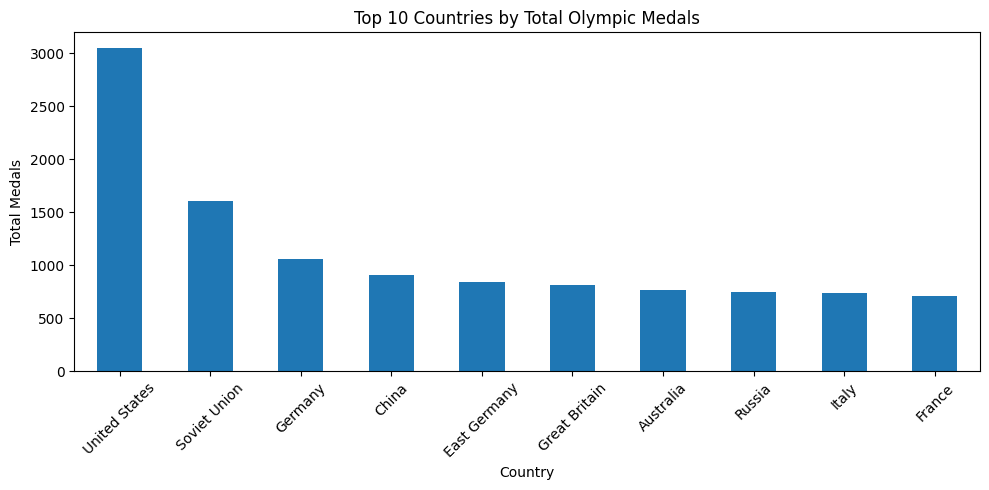


OLYMPICS MEDAL PREDICTION PROJECT COMPLETED!
Algorithm Used: Linear Regression
Features Used: ['athletes', 'prev_medals']
Target: Number of Olympic Medals
MAE: 4.322088753481257
RMSE: 8.185891289795407
R2 Score: 0.9185916946316627


In [1]:
# ==========================================================
# OLYMPICS MEDAL PREDICTION USING MACHINE LEARNING
# ==========================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries imported successfully!")


# 2. LOAD DATASET

url = "https://raw.githubusercontent.com/milouchev/Olympic-Medal-Prediction-ML-Python/main/teams.csv"

df = pd.read_csv(url)

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


# 3. EXPLORE DATASET

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


# 4. DATA CLEANING

df = df.dropna(subset=["medals"])

df = df.fillna({
    "age": df["age"].median(),
    "height": df["height"].median(),
    "weight": df["weight"].median(),
    "athletes": df["athletes"].median(),
    "events": df["events"].median(),
    "prev_medals": 0
})

print("\nMissing values handled!")
print(df.isnull().sum())


# 5. DATA VISUALIZATION

plt.figure(figsize=(8, 5))
sns.histplot(df["medals"], bins=30, kde=True)
plt.title("Distribution of Olympic Medals")
plt.xlabel("Number of Medals")
plt.ylabel("Frequency")
plt.show()


# 6. CORRELATION ANALYSIS

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()


# 7. ATHLETES VS MEDALS

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="athletes", y="medals")
plt.title("Number of Athletes vs Medals")
plt.xlabel("Number of Athletes")
plt.ylabel("Number of Medals")
plt.show()


# 8. SELECT FEATURES AND TARGET

features = ["athletes", "prev_medals"]

X = df[features]
y = df["medals"]

print("\nSelected Features:")
print(features)

print("\nTarget Variable: medals")


# 9. SPLIT TRAINING AND TESTING DATA

train = df[df["year"] < 2012]
test = df[df["year"] >= 2012]

X_train = train[features]
y_train = train["medals"]

X_test = test[features]
y_test = test["medals"]

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


# 10. TRAIN LINEAR REGRESSION MODEL

model = LinearRegression()

model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")

print("Model Coefficients:", model.coef_)
print("Model Intercept:", model.intercept_)


# 11. MAKE PREDICTIONS

predictions = model.predict(X_test)

print("\nActual vs Predicted Medals:")

results = pd.DataFrame({
    "Actual Medals": y_test.values,
    "Predicted Medals": predictions
})

display(results.head(15))


# 12. MODEL EVALUATION

mae = mean_absolute_error(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, predictions)

print("\nMODEL PERFORMANCE")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


# 13. ACTUAL VS PREDICTED GRAPH

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions, alpha=0.6)

plt.xlabel("Actual Medals")
plt.ylabel("Predicted Medals")

plt.title("Actual vs Predicted Olympic Medals")

plt.show()


# 14. RESIDUAL PLOT

residuals = y_test.values - predictions

plt.figure(figsize=(8, 5))

plt.scatter(predictions, residuals, alpha=0.6)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Medals")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()


# 15. TOP COUNTRIES BY MEDALS

top_countries = (
    df.groupby("country")["medals"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))

top_countries.plot(kind="bar")

plt.title("Top 10 Countries by Total Olympic Medals")
plt.xlabel("Country")
plt.ylabel("Total Medals")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 16. FINAL SUMMARY

print("\nOLYMPICS MEDAL PREDICTION PROJECT COMPLETED!")
print("Algorithm Used: Linear Regression")
print("Features Used:", features)
print("Target: Number of Olympic Medals")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

# Conclusion

In this project, we implemented a Machine Learning model to predict Olympic medal counts using historical Olympic data.

The following concepts were covered:

1. Data Loading and Exploration
2. Data Cleaning and Preprocessing
3. Exploratory Data Analysis
4. Correlation Analysis
5. Linear Regression
6. Model Training and Prediction
7. Model Evaluation and Visualization

Linear Regression was used to predict the number of medals based on features such as the number of athletes and previous medals.

The model was evaluated using MAE, MSE, RMSE, and R² Score.

Through this project, we gained practical knowledge of data preprocessing, visualization, regression, prediction, and model evaluation.